# Four-metric scientific interaction suite

Selected settings: off/155/001/003/046. Offline extraction from saved original Astra traces and native evaluations only. No new LLM calls, embeddings, annotations, or scientific runs. [Report](REPORT.md) · [Candidate caption and handoff](FIGURE_CAPTION.md) · [Plan](PLAN.md). Existing semantic, behavior, performance and recovery figures remain unchanged.

In [1]:
from pathlib import Path
import sys,json,csv,subprocess
from IPython.display import display,Markdown,Image,Code
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'Experiment/shared/task_selection.csv').exists())
sys.path.insert(0,str(ROOT/'Experiment/09_offline_metric_suite/code'))
import extract,analyze,report,plot,self_repetition
BASE=extract.BASE
REEXTRACT=False  # Reads frozen local files only.
RECOMPUTE=False  # Uses the saved extraction; no inference.
if REEXTRACT or not (extract.DATA/'snapshot.json').exists(): extract.main()
if RECOMPUTE or not (extract.DATA/'summary.json').exists(): analyze.main()
snap=json.loads((extract.DATA/'snapshot.json').read_text())
s=json.loads((extract.DATA/'summary.json').read_text())
report.main()
if REEXTRACT or RECOMPUTE or not (extract.DATA/'self_repetition_summary.json').exists(): self_repetition.main()
sr=json.loads((extract.DATA/'self_repetition_summary.json').read_text())
self_repetition.report(sr)
print(json.dumps({'policy':snap['policy'],'input_hashes':snap['provenance'],'bootstrap':s['bootstrap']},indent=2))

Report, caption, and status written.


{
  "policy": "Original endpoints only; no new LLM inference; existing native judgments reused.",
  "input_hashes": [
    {
      "path": "Experiment/01_behavioral_diversity/data/behavior_all_personas/snapshot.json",
      "sha256": "37e6d1029ed7690347d94c62d66e728e82e4f552794005c6e78946f740276e00"
    },
    {
      "path": "Experiment/02_performance_and_fields/data/all_available/snapshot.json",
      "sha256": "32653a253228c0a71f10f7b691c985fd7d9e36aadcc05880bce5769e6ce3569f"
    },
    {
      "path": "runs/repair-1-openai-astra-top10-trial-1-batch-2/original_results_snapshot.json",
      "sha256": "aae45594d7123c9c3a347003a0f772f97c61d6eea78679f04f7d605413d6af3d"
    },
    {
      "path": "runs/repair-1-openai-astra-top10-trial-2-batch-2/original_results_snapshot.json",
      "sha256": "4c5eb6c5ed5a49c198c0c178e0743b262ac6c23a9f3e4b5a8a49a42e6d9af01a"
    },
    {
      "path": "runs/repair-1-openai-astra-top10-trial-3-batch-2/original_results_snapshot.json",
      "sha256": "6337

## Current A: within-conversation self-repetition
Every later length-eligible message is compared with earlier messages of the same role and episode. The score is the percentage of its 40-character normalized windows previously observed, averaged over later turns, then available trials within question. The common five-setting question panel uses equal source weights. This detects verbatim reuse, not semantic loops. Initial/context text, code fences and blockquotes are excluded. Short/single-message conversations are unavailable. The first message supplies history, never a self-comparison. Widths 20/80 are sensitivities. See SELF_REPETITION.md for all limits.

In [2]:
display(Markdown((BASE/'SELF_REPETITION.md').read_text()))
print(json.dumps(sr['method'],indent=2))

# Within-conversation self-repetition

This replaces the cross-run structural heatmap in panel A. It uses saved original messages only, separated into simulator and actor roles. No LLM inference or new embeddings. B and D retain their previous values. The prior structural figure and notebook are archived under `revisions/v2_structural_A/`.

## Definition

For each later message of one role in a conversation, form every overlapping window of 40 normalized Unicode characters. Count a window as repeated if exactly the same window appeared in an earlier message of that same role and episode. Divide matched windows by all windows in the current message, then average these fractions across eligible later turns. Repeated windows inside the current message alone do not count. The first eligible message supplies history and is not scored.

Normalization: remove fenced code blocks and Markdown blockquote lines; Unicode NFKC and casefold; retain letters, combining marks and numbers, removing punctuation/whitespace. No word-tokenizer, translation, summaries or semantic judge. Simulator messages omit initial requests/inspection; actor messages are handoffs or SciConv clarification questions, excluding tool logs, transcript history and final SciConv specification. Naturally restated or unmarked quoted material remains part of the observed output.

The primary width of 40 was set before examining outcomes, following the existing 40-character opening analysis. Widths 20 and 80 are sensitivity checks, not alternatives selected by the result. Characters span languages differently; multilingual persona settings and code-heavy messages can affect this metric. It measures long verbatim phrase reuse, not semantic redundancy, unnecessary questioning, lack of progress, or mode collapse. Necessary scientific terms or facts may repeat legitimately.

## Aggregation and missingness

Require at least two messages of the same role with sufficient normalized length. Too-short or single-message conversations are unavailable, never zero. Average eligible original trials within question, retain questions eligible for all five settings, average questions within benchmark and then the five benchmarks equally. Simulator and actor panels are matched separately. Eligibility conditions on conversation length and successful trace completion. Longer conversations have more opportunities for reuse; this is descriptive and does not remove that confounding. Three-trial settings use their available eligible trials; 003/046 use one. Paired contrasts compare question means, not necessarily the same number of trials.

Pointwise 95% percentile CIs use 20,000 source-study cluster bootstrap draws, retaining each sampled study’s matched questions. Trial noise is conditional on saved repeats, not independently re-estimated. No significance stars or multiplicity-adjusted claims.

| Role | Window length | Common questions | Source counts |
|---|---|---|---|
| simulator | 20 | 81 | {"asibench": 7, "bixbench": 27, "discoverybench": 21, "expbench": 6, "sciconvbench": 20} |
| simulator | 40 | 80 | {"asibench": 7, "bixbench": 27, "discoverybench": 21, "expbench": 6, "sciconvbench": 19} |
| simulator | 80 | 78 | {"asibench": 7, "bixbench": 27, "discoverybench": 21, "expbench": 6, "sciconvbench": 17} |
| actor | 20 | 80 | {"asibench": 6, "bixbench": 27, "discoverybench": 21, "expbench": 6, "sciconvbench": 20} |
| actor | 40 | 76 | {"asibench": 6, "bixbench": 27, "discoverybench": 21, "expbench": 6, "sciconvbench": 16} |
| actor | 80 | 61 | {"asibench": 6, "bixbench": 23, "discoverybench": 21, "expbench": 6, "sciconvbench": 5} |

## Simulator results — 40 characters

| Setting | Repeated windows % [95% CI] | Paired difference vs off (pp) |
|---|---|---|
| Off | 0.10 [0.05, 0.18]; n=80, g=57 | Reference |
| 155 | 0.16 [0.01, 0.38]; n=80, g=57 | 0.05 [-0.11, 0.26]; n=80, g=57 |
| 001 | 0.09 [0.03, 0.16]; n=80, g=57 | -0.01 [-0.11, 0.08]; n=80, g=57 |
| 003 | 0.14 [0.01, 0.34]; n=80, g=57 | 0.04 [-0.09, 0.23]; n=80, g=57 |
| 046 | 0.40 [0.10, 0.82]; n=80, g=57 | 0.29 [-0.00, 0.70]; n=80, g=57 |

## Actor results — 40 characters

| Setting | Repeated windows % [95% CI] | Paired difference vs off (pp) |
|---|---|---|
| Off | 0.05 [0.02, 0.09]; n=76, g=53 | Reference |
| 155 | 0.00 [0.00, 0.00]; n=76, g=53 | -0.05 [-0.09, -0.01]; n=76, g=53 |
| 001 | 0.06 [0.02, 0.14]; n=76, g=53 | 0.01 [-0.06, 0.10]; n=76, g=53 |
| 003 | 0.00 [0.00, 0.01]; n=76, g=53 | -0.05 [-0.08, -0.01]; n=76, g=53 |
| 046 | 0.03 [0.01, 0.06]; n=76, g=53 | -0.02 [-0.07, 0.04]; n=76, g=53 |

## Sensitivity to phrase length

| Role | Window | Off | 155 | 001 | 003 | 046 |
|---|---|---|---|---|---|---|
| simulator | 20 | 2.1012 | 1.3460 | 1.7987 | 2.0522 | 2.8271 |
| simulator | 40 | 0.1031 | 0.1554 | 0.0910 | 0.1429 | 0.3977 |
| simulator | 80 | 0.0074 | 0.0000 | 0.0000 | 0.0000 | 0.0280 |
| actor | 20 | 1.2982 | 0.2135 | 1.0026 | 0.5744 | 1.3197 |
| actor | 40 | 0.0519 | 0.0006 | 0.0634 | 0.0045 | 0.0291 |
| actor | 80 | 0.0000 | 0.0000 | 0.0000 | 0.0000 | 0.0000 |

Sensitivity panels can have different eligible questions; coverage is reported above. The primary simulator contrasts all have CIs including zero. The data do not establish that persona injection reduces within-conversation simulator self-repetition. Low lexical repetition does not rule out semantic or strategic repetition.

## Figure and data

[Main figure](figures/metric_suite.pdf) · [Separate simulator/actor distributions](figures/self_repetition_roles.pdf) · [Executed notebook](metric_suite.ipynb). A shows mean/CI because most case-level values are zero and a few outliers dominate the raw scale. Supporting violins show source-balanced KDEs (Scott bandwidth; observed range; equal maximum width), case dots, source-balanced mean and CI. Density is not uncertainty.

CSV files under data/: `self_repetition_episodes`, `self_repetition_turns`, `self_repetition_cases`, `self_repetition_cells`, `self_repetition_contrasts`. They contain numbers and hashes, not message text. Frozen trace hashes are checked on extraction.

`OPENBLAS_NUM_THREADS=1 .venv/bin/python Experiment/09_offline_metric_suite/code/self_repetition.py` regenerates the extraction, statistics and this report.


{
  "primary_window": 40,
  "sensitivity_windows": [
    20,
    40,
    80
  ],
  "unit": "normalized Unicode characters, preserving letters/numbers/combining marks",
  "within_trace": "mean repeated-window fraction over later length-eligible same-role turns",
  "question": "mean over available eligible original trials",
  "aggregate": "common five-setting questions; equal questions within source, equal represented-source weights",
  "ci": "20000 source-study cluster percentile draws, conditional on saved trials",
  "interpretation": "verbatim cross-turn reuse; not judged semantic redundancy or mode collapse",
  "normalization": "NFKC, casefold, strip fenced code and blockquote lines, remove punctuation/whitespace",
  "source_sha256": "e8b5ef303ce837826e331b8c7527188a1ed3194223637aef06ca2a21e04548d3"
}


## Coverage and matching
All metrics use original endpoints. Trace repetition uses a common panel with ≥2 complete traces for off/155/001 and ≥1 for 003/046; no invented within-persona repetitions for single-trial settings. Native outcome panels use all eligible original scores. Fact recovery uses only disambiguation; binary failure coverage uses only Bix correctness and SciConv FRR. Populations differ across panels and are explicitly reported.

In [3]:
from collections import Counter
print('Original slots:',len(snap['scores']))
print('Complete traces:',sum(r.get('exclusion') is None for r in snap['traces']))
print('Saved recovery judgements:',sum(r['recovery'] is not None for r in snap['recovery']))
print('Repetition panel:',dict(Counter(r['source'] for r in s['repetition_coverage'])))
print('Failure panel:',dict(Counter(r['source'] for r in s['failure_panel'])))
display(Markdown(report.table(['Source','Off','155','001','003','046'],[[source,*[sum(r.get('exclusion') is None and r['source']==source and r['arm']==a for r in snap['traces']) for a in extract.ARMS]] for source in extract.SOURCES])))

Original slots: 2200
Complete traces: 1958
Saved recovery judgements: 220
Repetition panel: {'asibench': 7, 'bixbench': 27, 'discoverybench': 21, 'expbench': 5, 'sciconvbench': 40}
Failure panel: {'bixbench': 26, 'sciconvbench': 40}


| Source | Off | 155 | 001 | 003 | 046 |
|---|---|---|---|---|---|
| asibench | 93 | 96 | 109 | 8 | 23 |
| bixbench | 117 | 117 | 119 | 28 | 37 |
| discoverybench | 115 | 107 | 115 | 22 | 37 |
| expbench | 120 | 105 | 105 | 6 | 39 |
| sciconvbench | 120 | 120 | 120 | 40 | 40 |

## Estimators
**Repetition:** for each question, fraction of identical canonical event sequences across persona-rollout pairs; within-persona cells use distinct repeats only. Equal question weights within benchmark and equal benchmark weights in the aggregate. Lower repetition describes more structural variation, not better science. **Recovery:** saved recovered/total deleted-fact counts, averaged within case across observed trials. **Native scores:** retain each source’s native scale; paired contrasts require matching task/trial and compatible evaluators. **Failure coverage:** enumerate size-m off-trial subsets versus size-m distinct-persona subsets, choosing each persona’s available trial uniformly. At m=1,2,3, estimate expected fraction of questions with ≥1 native scientific failure. No best-performing/worst-performing persona subset is chosen. Study-cluster bootstrap CIs condition on the observed trials. No new significance tests.

In [4]:
display(Markdown(report.table(['Setting','Complete-fact recovery [95% CI]','Matched change from off'],[[label,report.cell(report.pick(s['outcomes'],metric='complete_fact_recovery',arm=a,level='all',group='all')),'Reference' if a==extract.ARMS[0] else report.cell(report.pick(s['contrasts'],metric='complete_fact_recovery',persona_i=a,persona_j=extract.ARMS[0],level='all',group='all'))] for a,label in zip(extract.ARMS,extract.LABELS)])))
display(Markdown(report.table(['Benchmark','Budget','Off','Mixture','Matched difference'],[[report.NAMES[source],m,*[report.cell(report.pick(s['failure_coverage'],variant='primary',level='source',group=source,budget=m,strategy=strategy)) for strategy in ['off','mixture','difference']]] for source in ['bixbench','sciconvbench'] for m in [1,2,3]])))
print('Aggregate repetition:',json.dumps(s['repetition_overview'],indent=2))

| Setting | Complete-fact recovery [95% CI] | Matched change from off |
|---|---|---|
| Off | 78.33 [60.00, 93.33]; n=20, g=20 | Reference |
| 155 | 85.00 [70.00, 98.33]; n=20, g=20 | 6.67 [-3.33, 20.00]; n=20, g=20 |
| 001 | 83.33 [66.67, 96.67]; n=20, g=20 | 5.00 [0.00, 13.33]; n=20, g=20 |
| 003 | 80.00 [60.00, 95.00]; n=20, g=20 | 0.00 [-15.00, 15.00]; n=20, g=20 |
| 046 | 75.00 [55.00, 90.00]; n=20, g=20 | -5.00 [-15.00, 0.00]; n=20, g=20 |

| Benchmark | Budget | Off | Mixture | Matched difference |
|---|---|---|---|---|
| BixBench | 1 | 61.54 [36.36, 88.00]; n=26, g=20 | 61.54 [36.36, 88.00]; n=26, g=20 | 0.00 [0.00, 0.00]; n=26, g=20 |
| BixBench | 2 | 61.54 [36.36, 88.00]; n=26, g=20 | 61.54 [36.36, 88.00]; n=26, g=20 | 0.00 [0.00, 0.00]; n=26, g=20 |
| BixBench | 3 | 61.54 [36.36, 88.00]; n=26, g=20 | 61.54 [36.36, 88.00]; n=26, g=20 | 0.00 [0.00, 0.00]; n=26, g=20 |
| SciConvBench | 1 | 15.00 [5.83, 25.00]; n=40, g=40 | 16.25 [8.54, 25.21]; n=40, g=40 | 1.25 [-5.83, 8.33]; n=40, g=40 |
| SciConvBench | 2 | 19.17 [7.50, 31.67]; n=40, g=40 | 23.94 [13.89, 35.05]; n=40, g=40 | 4.77 [-5.42, 15.28]; n=40, g=40 |
| SciConvBench | 3 | 20.00 [7.50, 32.50]; n=40, g=40 | 29.44 [17.57, 42.01]; n=40, g=40 | 9.44 [-1.32, 21.25]; n=40, g=40 |

Aggregate repetition: {
  "between_all_pairs": {
    "mean": 83.5627572016461,
    "ci95": [
      79.13709529645192,
      87.65191888547533
    ],
    "tasks": 100,
    "episodes": 1000,
    "studies": 77,
    "source_counts": {
      "asibench": 7,
      "bixbench": 27,
      "discoverybench": 21,
      "expbench": 5,
      "sciconvbench": 40
    },
    "studies_by_source": {
      "asibench": 7,
      "bixbench": 20,
      "discoverybench": 5,
      "expbench": 5,
      "sciconvbench": 40
    },
    "singleton_sources": []
  },
  "between_minus_within_off": {
    "mean": -1.6162551440329231,
    "ci95": [
      -5.135796904335213,
      2.187770655270636
    ],
    "tasks": 100,
    "episodes": 1000,
    "studies": 77,
    "source_counts": {
      "asibench": 7,
      "bixbench": 27,
      "discoverybench": 21,
      "expbench": 5,
      "sciconvbench": 40
    },
    "studies_by_source": {
      "asibench": 7,
      "bixbench": 20,
      "discoverybench": 5,
      "expbench": 5,
  

## Revised individual-setting coverage
The main figure replaces the mixture with each setting separately on the same 40 SciConv questions. Average all size-m subsets without replacement within each setting. Three-trial settings support budgets 1–3; 003/046 support only budget 1. The mixture table above remains supplementary. In B, a run scores 1 only if all annotated missing facts are recovered. Each dot is the percentage of complete-recovery runs for one case; the violin smooths these discrete proportions, and the black bar is a confidence interval for the equal-case mean. This is an endpoint change using existing runs, not a newly harder protocol.

In [5]:
display(Markdown(report.table(['Setting','Budget','Failed-task coverage [95% CI]'],[[extract.LABELS[extract.ARMS.index(r['arm'])],r['budget'],report.cell(r)] for r in s['persona_failure_coverage']])))

| Setting | Budget | Failed-task coverage [95% CI] |
|---|---|---|
| Off | 1 | 15.00 [5.83, 25.00]; n=40, g=40 |
| Off | 2 | 19.17 [7.50, 31.67]; n=40, g=40 |
| Off | 3 | 20.00 [7.50, 32.50]; n=40, g=40 |
| 155 | 1 | 15.00 [7.50, 24.17]; n=40, g=40 |
| 155 | 2 | 22.50 [11.67, 34.17]; n=40, g=40 |
| 155 | 3 | 27.50 [15.00, 42.50]; n=40, g=40 |
| 001 | 1 | 10.00 [2.50, 18.33]; n=40, g=40 |
| 001 | 2 | 13.33 [4.17, 24.17]; n=40, g=40 |
| 001 | 3 | 15.00 [5.00, 27.50]; n=40, g=40 |
| 003 | 1 | 17.50 [7.50, 30.00]; n=40, g=40 |
| 046 | 1 | 22.50 [10.00, 35.00]; n=40, g=40 |

## Rendered figures
Main and supporting figures use the established semantic-figure typography and persona palette. The earlier structural matrices remain supplementary; the current A compares each later message with earlier same-role messages within its own conversation. The revised main figure retains A/B/D: A is within-conversation simulator verbatim self-repetition, B is a violin of case-level complete-recovery rates with mean/CI, and D shows individual settings on SciConv only. Native scores are reported separately. 003/046 stop at budget 1; no unavailable repeats are fabricated. All source data are retained. Shaded coverage bands are pointwise 95% CIs, not variation across independently regenerated campaigns.

"""Paper-ready four-metric figures, matching the established semantic-figure palette."""
import sys,json,csv
from collections import defaultdict
from pathlib import Path
import numpy as np
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
from matplotlib.patches import Rectangle
from extract import ROOT,BASE,DATA,ARMS,SOURCES,FAMILIES,LABELS,write_csv
sys.path.insert(0,str(ROOT/'Experiment/01_behavioral_diversity/code'))
from audit_panel_alignment import require_matplotlib_panel_alignment
FIG=BASE/'figures';COLORS=['#0072B2','#E69F00','#009E73','#CC79A7','#D55E00']
NAMES=dict(zip(SOURCES,['ASI-Bench','BixBench','DiscoveryBench','EXP-Bench','SciConvBench']))
NAMES.update(dict(zip(FAMILIES,['Life sciences','Physical / engineering','Math / CS','Social / humanities'])))
plt.rcParams.update({'font.family':'sans-serif','font.sans-serif':['DejaVu Sans'],'font.size':7,'axes.labelsize':7,'axes.titlesize':8,'xtick.labelsize':6,'ytick.labelsize':6,'svg.fonttype':'none','pdf.fonttype':42,'axes.spines.top':False,'axes.spines.right':False,'axes.linewidth':.6})

def pick(rows,**kw):
 match=[r for r in rows if all(r.get(k)==v for k,v in kw.items())]
 assert len(match)==1,(kw,len(match))
 return match[0]

def axes_clean(ax):
 for spine in ax.spines.values():spine.set_visible(False)
 ax.tick_params(length=0,pad=4)

def repetition_heat(ax,s,level='all',group='all',variant='primary'):
 matrix=np.full((5,5),np.nan)
 for i,a in enumerate(ARMS):
  for j,b in enumerate(ARMS[:i+1]):
   r=pick(s['repetition'],persona_i=a,persona_j=b,level=level,group=group,variant=variant)
   if r['mean'] is not None:matrix[i,j]=r['mean']
 cmap=plt.get_cmap('PuBuGn').copy();cmap.set_bad('white');im=ax.imshow(matrix,cmap=cmap,vmin=0,vmax=100,aspect='auto')
 for i in range(5):
  for j in range(i+1):
   m=matrix[i,j]
   if np.isnan(m):ax.add_patch(Rectangle((j-.5,i-.5),1,1,facecolor='#EEEEEE',edgecolor='none'));txt='—';color='#777777'
   else:txt=f'{m:.1f}';color='white' if m>65 else '#182229'
   ax.text(j,i,txt,ha='center',va='center',fontsize=7,color=color)
 ax.set_xticks(range(5),LABELS);ax.set_yticks(range(5),LABELS);axes_clean(ax)
 return im

def score_heat(ax,s,field,groups,show_ci=False):
 matrix=np.array([[pick(s['outcomes'],metric='native_score',arm=a,level=field,group=g)['mean'] for g in groups] for a in ARMS],float)
 cmap=plt.get_cmap('Blues').copy();cmap.set_bad('#EEEEEE');im=ax.imshow(matrix,cmap=cmap,vmin=0,vmax=100,aspect='auto')
 for i,a in enumerate(ARMS):
  for j,g in enumerate(groups):
   r=pick(s['outcomes'],metric='native_score',arm=a,level=field,group=g);m=r['mean'];ci=r['ci95']
   txt='—' if m is None else f'{m:.1f}'
   if show_ci:txt+='\n'+(f'[{ci[0]:.1f}, {ci[1]:.1f}]' if ci else 'CI unavailable')
   ax.text(j,i,txt,ha='center',va='center',fontsize=6.5 if show_ci else 7,color='white' if m is not None and m>65 else '#182229',linespacing=1.4)
 labels=[NAMES[g].replace('DiscoveryBench','Discovery\nBench').replace('SciConvBench','SciConv\nBench').replace('Physical / engineering','Physical /\nengineering').replace('Social / humanities','Social /\nhumanities')+('*' if g=='asibench' else '') for g in groups]
 ax.set_xticks(range(len(groups)),labels);ax.set_yticks(range(5),LABELS);axes_clean(ax)
 return im

def self_repetition_violin(ax,role):
 from scipy.stats import gaussian_kde
 from collections import Counter
 sr=json.loads((DATA/'self_repetition_summary.json').read_text())
 for i,arm in enumerate(ARMS):
  rows=[r for r in sr['cases'] if r['arm']==arm and r['role']==role and r['width']==40 and r['panel']=='common']
  values=np.array([r['value'] for r in rows]);counts=Counter(r['source'] for r in rows)
  w=np.array([1/len(counts)/counts[r['source']] for r in rows])
  if len(values)>1 and np.ptp(values)>1e-8:
   kde=gaussian_kde(values,weights=w,bw_method='scott');grid=np.linspace(values.min(),values.max(),150)
   density=kde(grid);width=.38*density/density.max()
   ax.fill_betweenx(grid,i-wi

Saved main figure and two supporting figures.


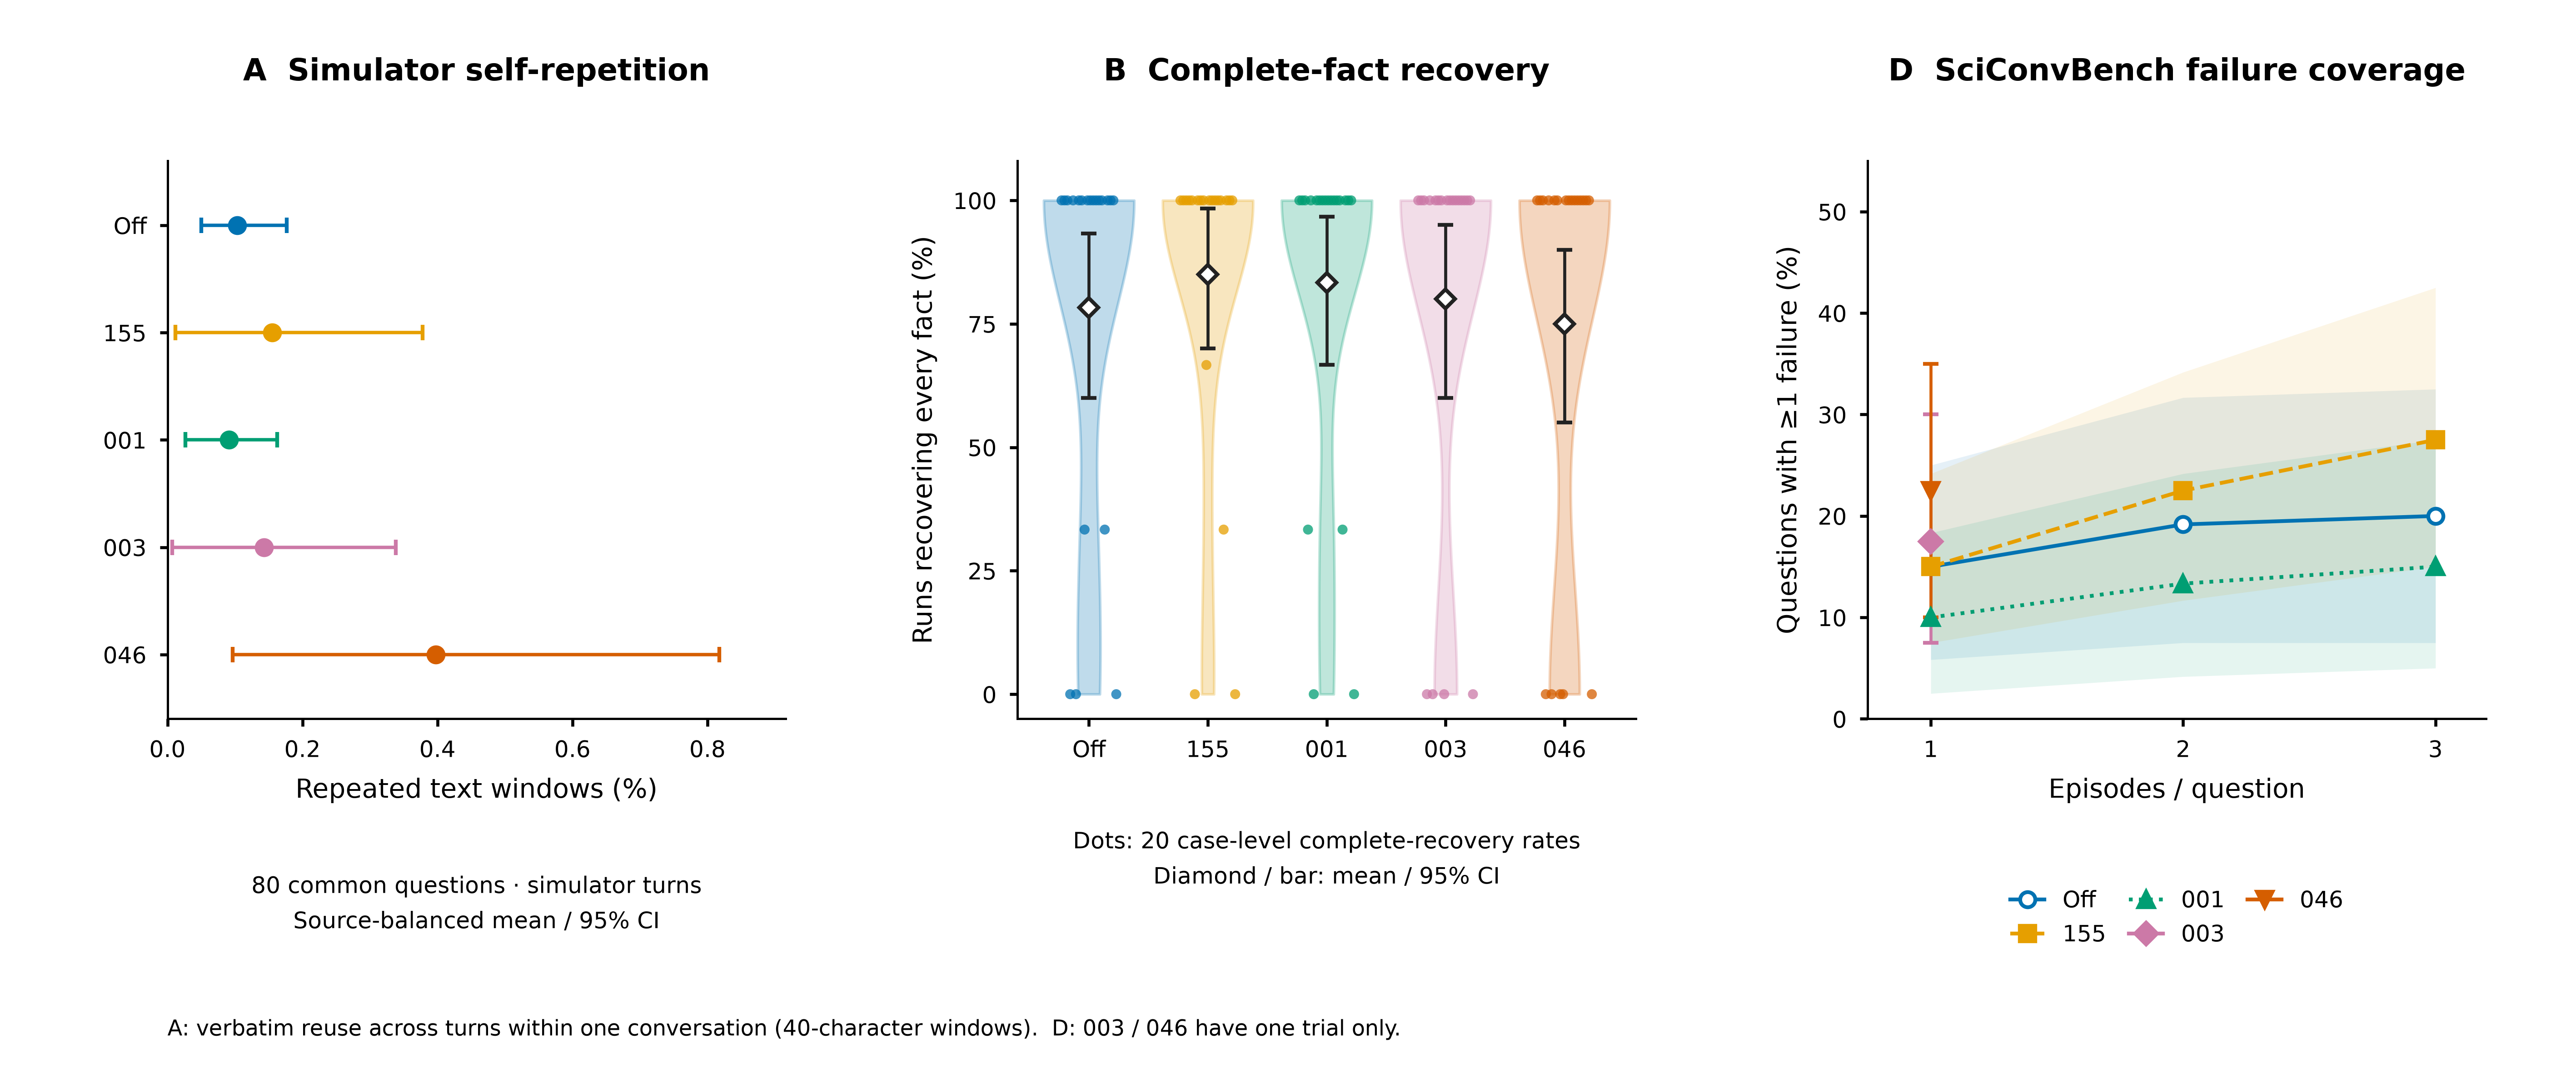

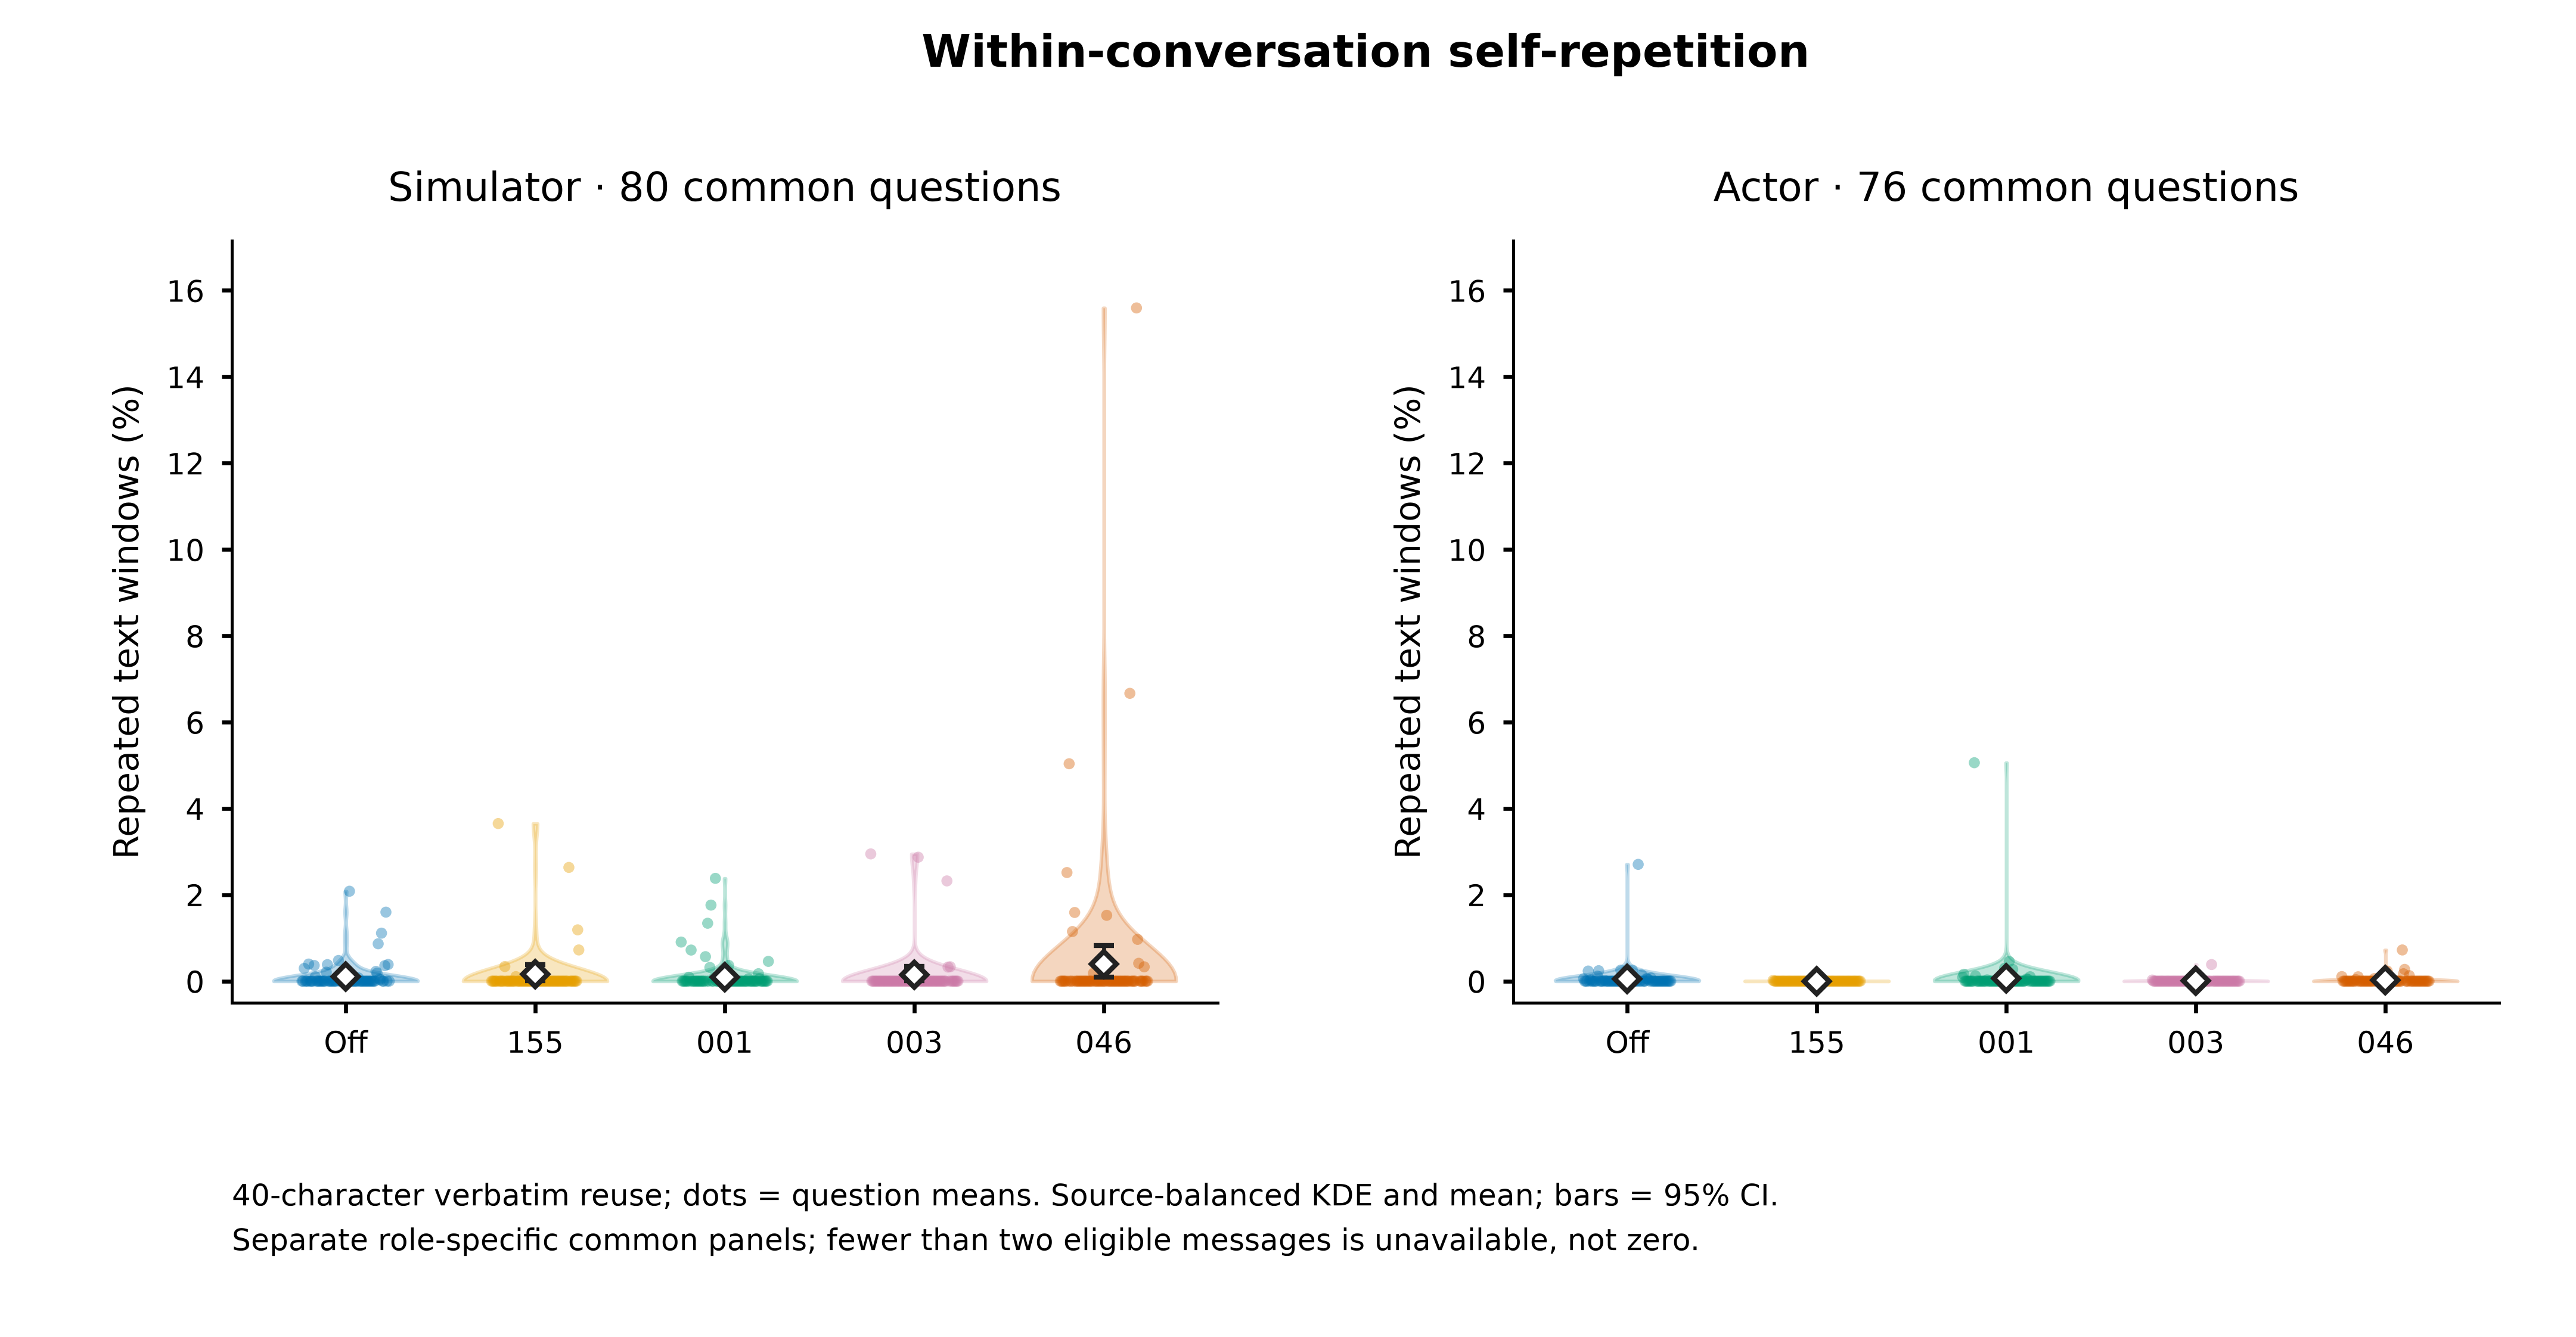

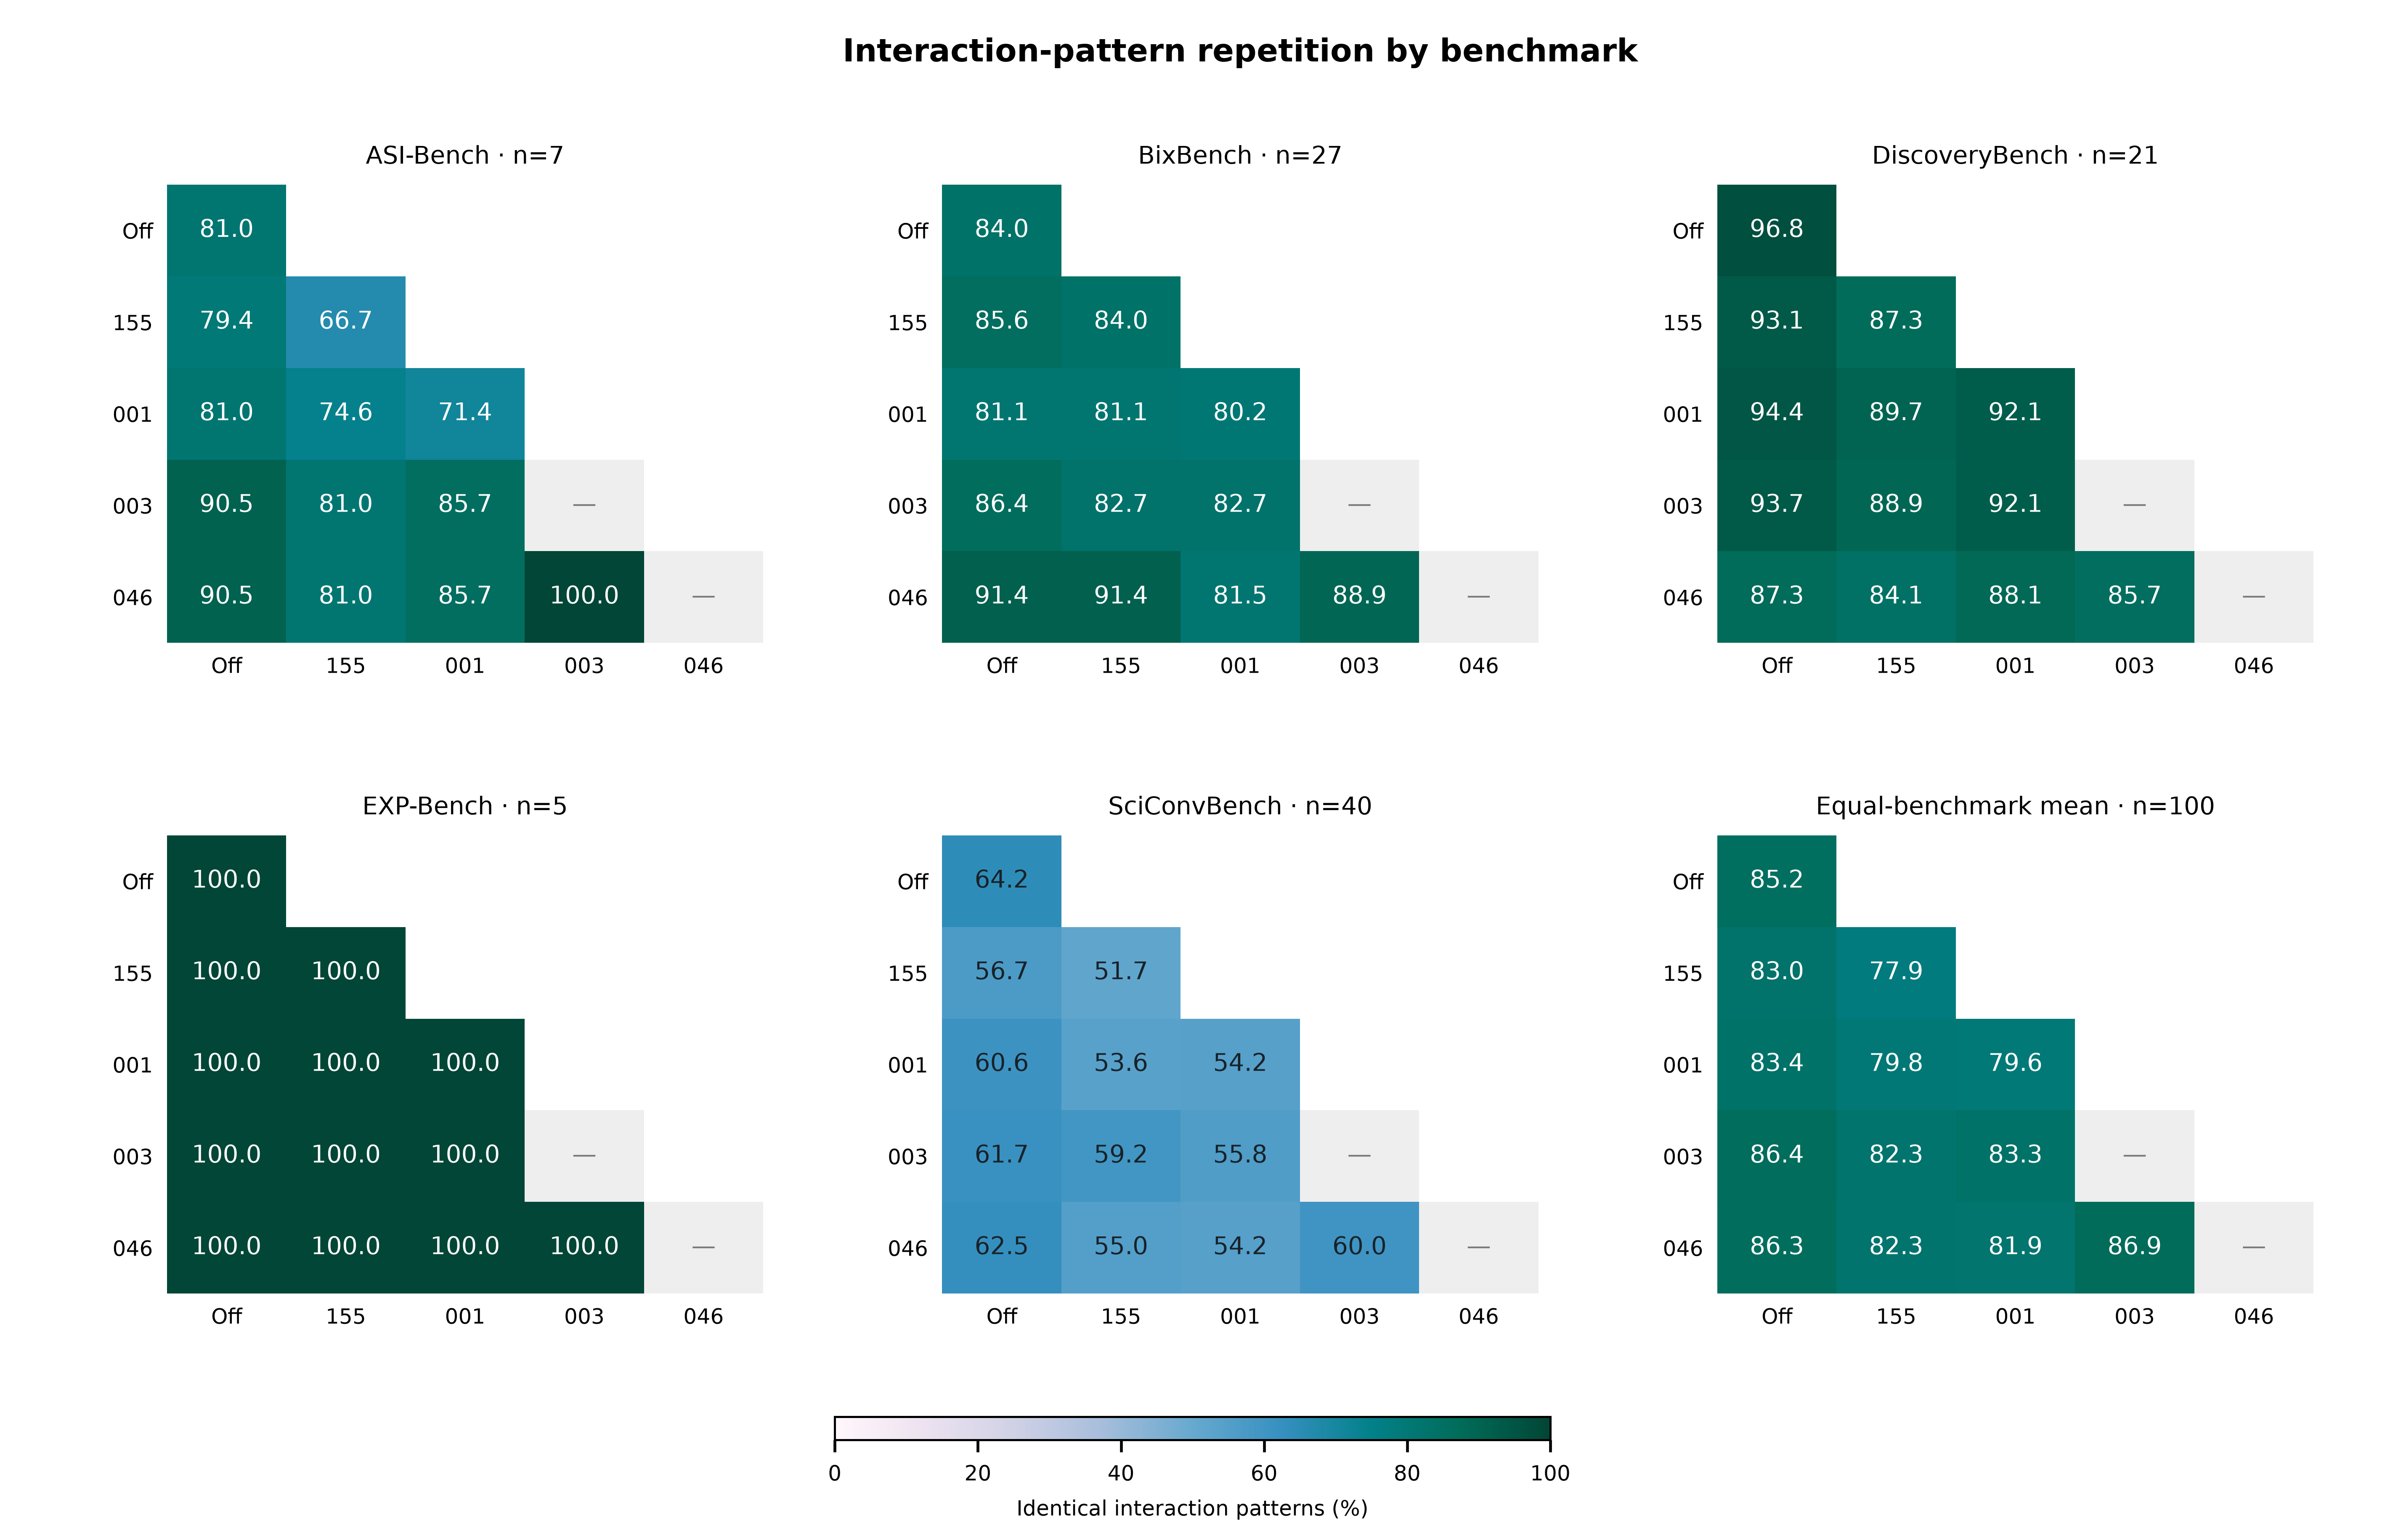

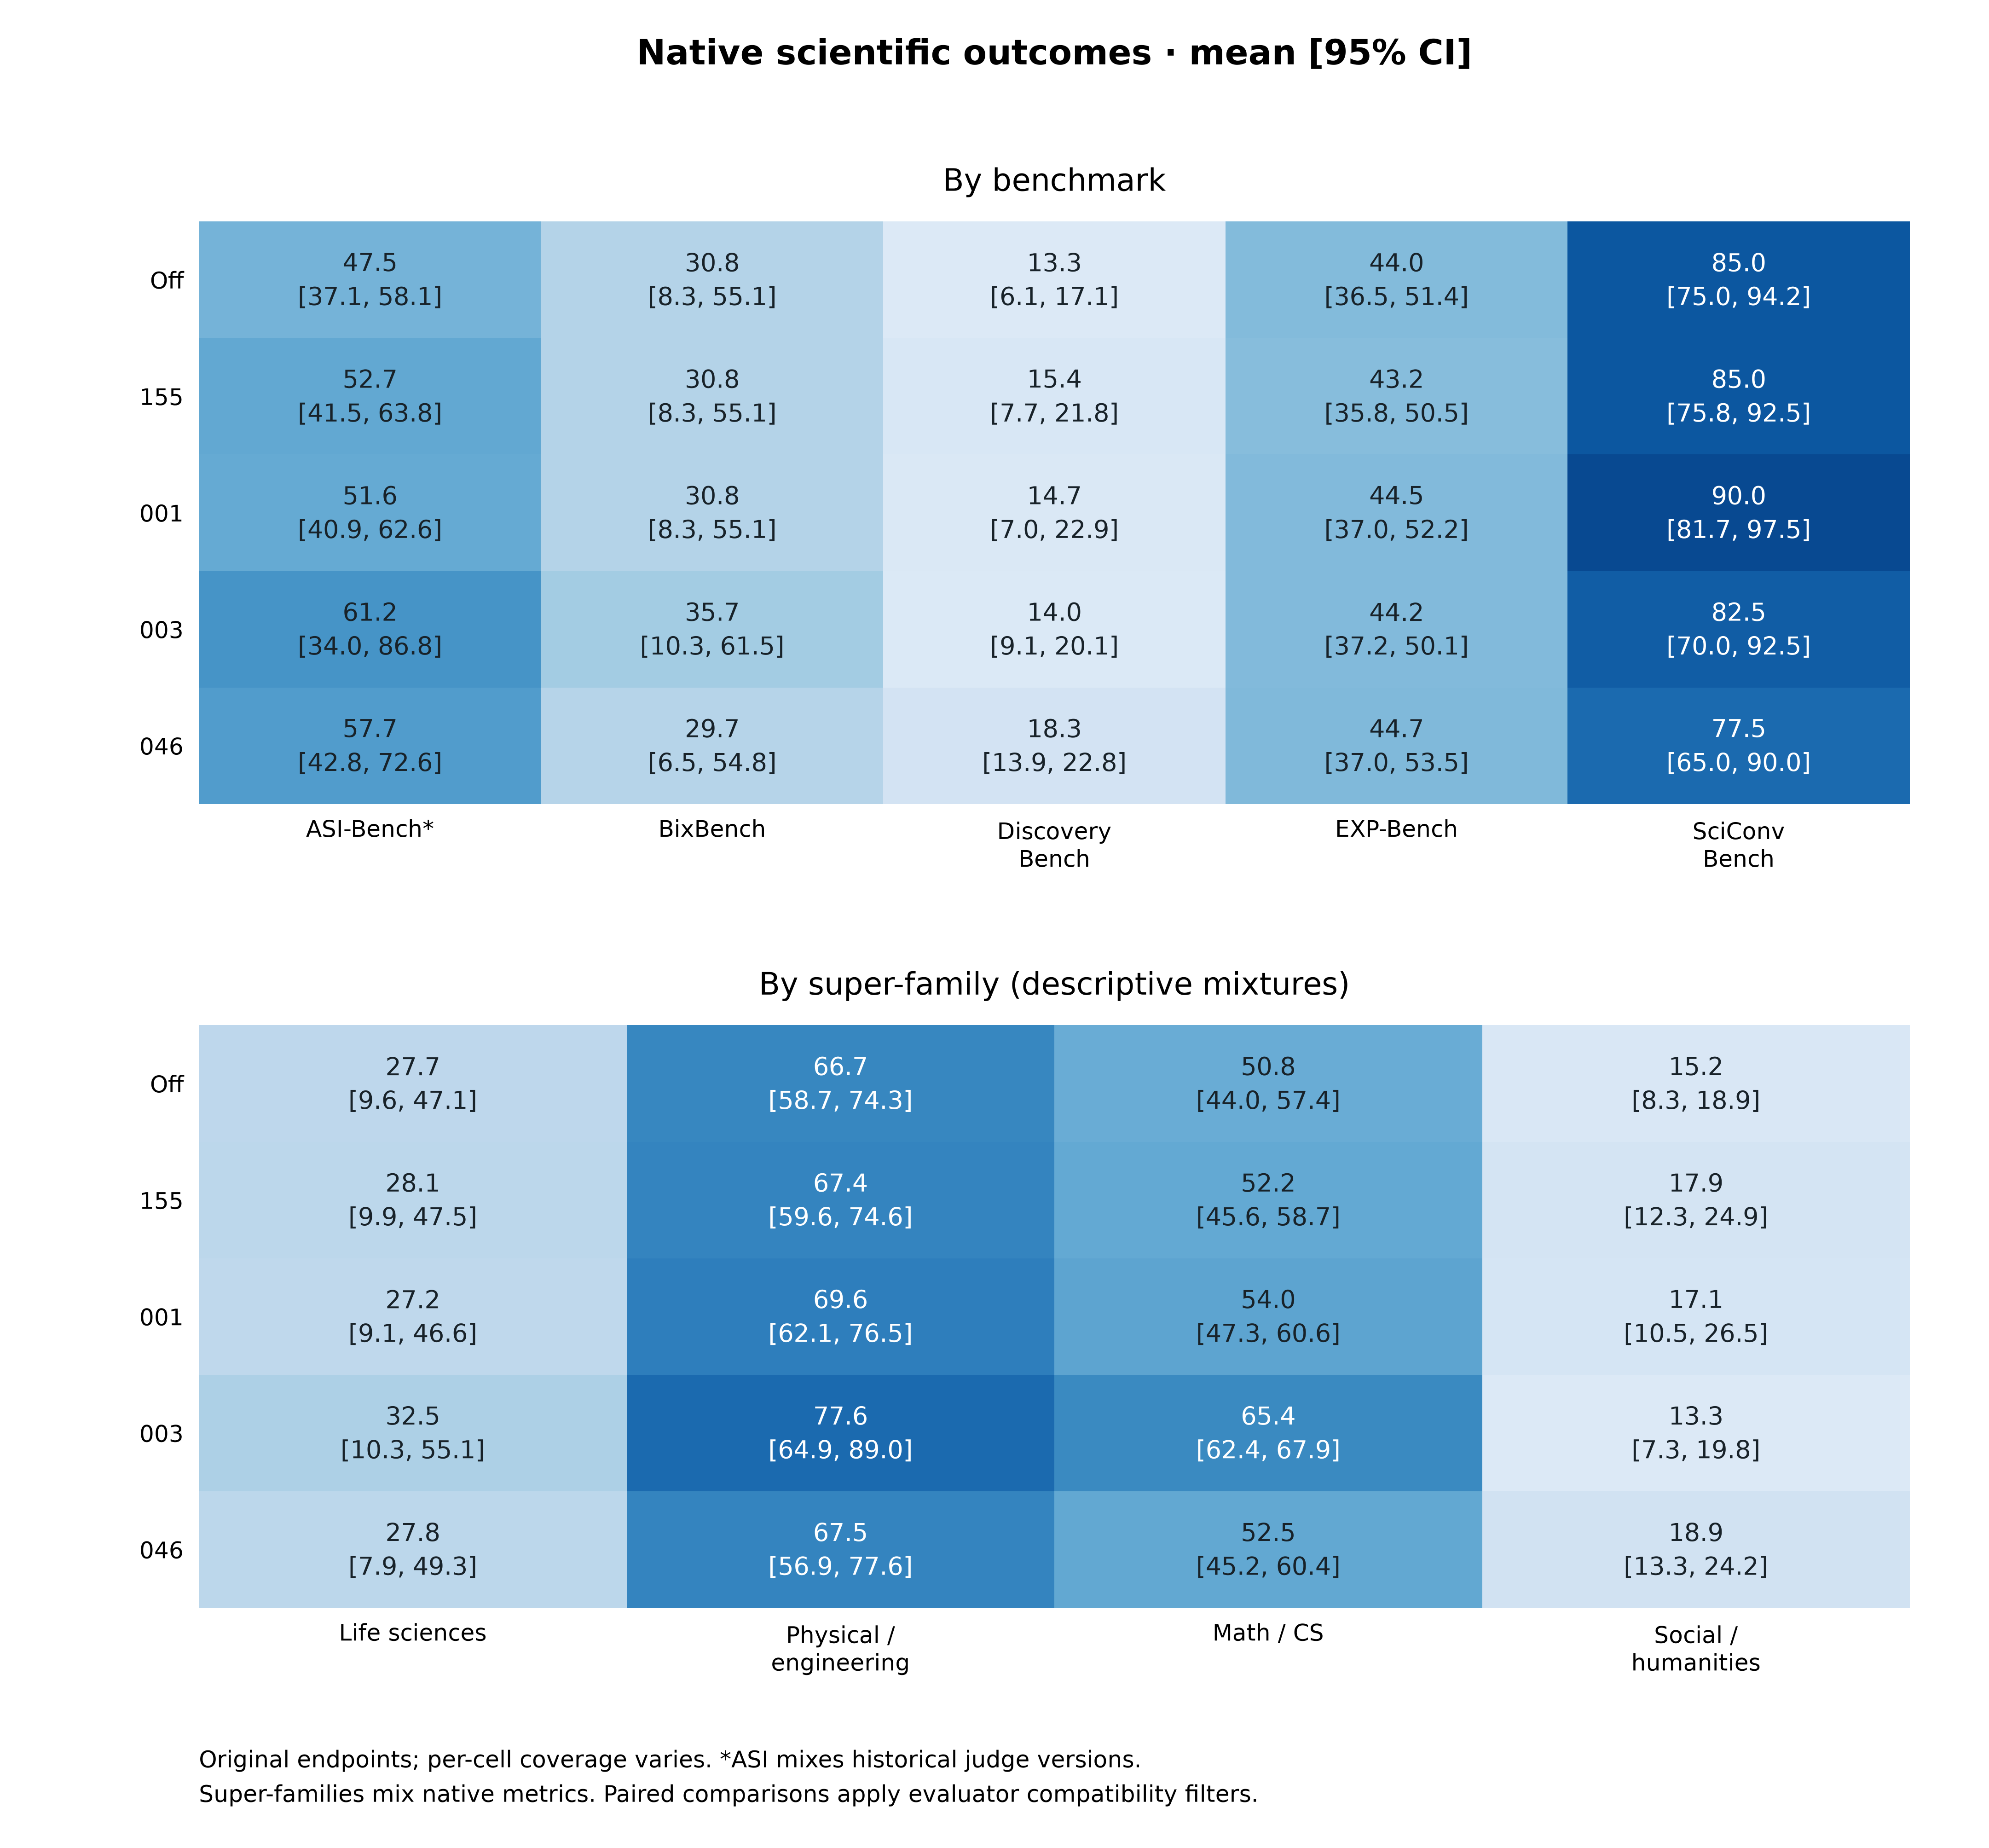

In [6]:
display(Code(Path(plot.__file__).read_text(),language='python'))
plot.main()
for name in ['metric_suite','self_repetition_roles','repetition_by_benchmark','native_scores_with_ci']:
    display(Image(filename=str(plot.FIG/(name+'.png')),width=1250))

## Sensitivities and interpretation
Same-length structural comparisons remove exchange-count differences but change eligible pair coverage. SciConv’s same-length patterns are identical by protocol construction; do not interpret its lower raw repetition as semantic strategy diversity. Intent-preserved failure coverage conditions on native intent flags, is secondary and does not prove full factual fidelity. Earlier recovery CIs used domain stratification; this integrated suite uses source-study clusters, so intervals can differ although means reproduce. Native absolute ASI scores mix historical evaluators; paired comparisons enforce corrected judges. Full methods and cell denominators are in REPORT.md.

In [7]:
checks=subprocess.run([sys.executable,str(BASE/'code/test_metrics.py')],capture_output=True,text=True,check=True)
print(checks.stdout+checks.stderr)
print('Same-length SciConv matched pattern rates:',sorted({round(r['mean'],8) for r in s['repetition'] if r['variant']=='same_length' and r['level']=='source' and r['group']=='sciconvbench' and r['mean'] is not None}))
display(Markdown((BASE/'FIGURE_CAPTION.md').read_text()))

.........
----------------------------------------------------------------------
Ran 9 tests in 0.153s

OK

Same-length SciConv matched pattern rates: [100.0]


# Candidate manuscript caption

**Within-conversation self-repetition, fact recovery and failure coverage under five simulator settings.** Off, 155, 001, 003 and 046 use saved original Astra-low episodes; off/155/001 have three trials and 003/046 one. **A**, simulator verbatim self-repetition: the fraction of overlapping 40-character normalized text windows in a later simulator message that occurred in any earlier simulator message of the same conversation, averaged over eligible later messages and available trials within question. Points and bars show source-balanced means and pointwise 95% CIs on 80 questions eligible for all settings (ASI 7, Bix 27, Discovery 21, EXP 6, SciConv 19). Each question requires at least two length-eligible simulator messages in an available trial. This measures lexical reuse, not judged semantic redundancy or mode collapse. **B**, complete-fact recovery on 20 SciConv disambiguation cases: a run scores 1 only if every annotated missing fact is recovered, before intent gating. Colored dots are the within-case percentages of fully recovered runs; violins show Scott-bandwidth Gaussian KDEs restricted to observed ranges and scaled to equal maximum width. White diamonds and black bars show equal-case means and 95% CIs. Case proportions are discrete (0/33.3/66.7/100% with three trials; 0/100% with one), and the violin smoothing is descriptive. **D**, expected percentage of 40 common SciConv questions with at least one native scientific failure when selecting m episodes of each setting. All size-m subsets of its saved trials are averaged without replacement. Off/155/001 support budgets 1–3; 003/046 support only 1. Bands and single-point error bars show 95% CIs. Higher failure coverage is not higher task success. CIs use 20,000 source-study cluster bootstrap draws conditional on saved trials. Different panels have different eligible populations. Native performance is reported separately; panel letters retain prior identifiers during revision.

## Agent handoff

Current A replaces the prior cross-persona structural heatmap. Read SELF_REPETITION.md for preprocessing, formula, eligibility, multilingual/length limitations, 20/80-character sensitivity, actor results and source data. A excludes initial requests, system/context text, fenced code and Markdown blockquotes; all natural restatements otherwise remain. Text is normalized with NFKC/casefold, keeping Unicode letters/marks/numbers. Short or single-message traces are unavailable, not zero. Role-specific common panels differ (simulator 80; actor 76). A uses equal benchmark weights, while B/D give questions equal weight within SciConv. No causal or semantic-collapse conclusion is supported by lexical overlap alone. B replaces partial recovery with all-or-nothing complete recovery using the same existing runs; A and D are unchanged. This endpoint revision does not create new harder tasks. Partial-recovery B is archived under revisions/v3_partial_recovery/. D must not extend single-trial settings beyond budget 1. All prior figure versions are under revisions/. No new LLM inference or embeddings were used. Relabel D to C only when final manuscript numbering is settled.
